# 18 – Modelldaten: Stundenwerte, Kennzahlen und Labels je Zähler

**Zweck:** Dieses Notebook baut noch kein Modell. Es stellt die Daten bereit, aus
denen die Notebooks 19 bis 22 lernen, und legt fest, was ein Modell überhaupt
erkennen soll. Alles, was später gemessen wird, hängt an diesen Entscheidungen —
deshalb stehen sie hier einzeln und nachvollziehbar.

**Woher die Bausteine kommen**

| Notebook / Modul | liefert | wofür hier |
|---|---|---|
| [`00_eda`](00_eda_hast_stationsprofile.ipynb) | `real_meters/<Zähler>.csv`: eine bereinigte Stundenreihe je Zähler, lückenloses Raster | die Messwerte |
| [`00_eda`](00_eda_hast_stationsprofile.ipynb) | `hast_features.csv` mit dem Anschlusswert je Zähler | die Auslastung |
| `src/weather.py` | Außentemperatur DWD Kitzingen | Wetter als Eingang der Modelle |
| `src/inspections.py` | Ja/Nein-Kästchen der Begehungen | Labels |
| `src/befundcodes.py` ([`15_befunde`](15_befunde.ipynb)) | Fehlerlabels aus dem Freitext | Labels |
| `src/load_begehungen.py` ([`03_wirkungsanalyse`](03_wirkungsanalyse_begehungen.ipynb)) | Adresse → Zählernummer inkl. Zählerwechsel | Labels je Zähler |

**Die wichtigste Regel für alle folgenden Notebooks:** Ein Modell, das Fehler
*vorhersagen* soll, darf nur sehen, was **vor** der Begehung gemessen wurde.
Nach der Begehung ist der Fehler ja schon behoben. Stichtag ist der
**1. September 2024**; davor lag nur eine Handvoll Begehungen, und bei diesen
Zählern endet der Blick schon am Tag ihrer Begehung.

**Ergebnis:** drei Dateien in `data/processed/` — `modell_stunden.parquet`,
`modell_kennzahlen.csv`, `modell_labels.csv`.

## Wie es zu diesen Notebooks kam

Bevor es an die Daten geht, ein Blick zurück. Die Notebooks 18 bis 23 sind nicht der
erste Versuch, Fehler an den HAST zu finden. Im Team und in meiner eigenen Vorarbeit
wurde vieles probiert. Jeder Versuch hat etwas gezeigt, und meistens war es, warum
er *nicht* reicht:

| Versuch | wo | Ergebnis | was daraus folgte |
|---|---|---|---|
| Regeln mit festen Schwellen (5 Fehlerfamilien) | `src/fault_detection.py` | auf synthetischen Daten 100 %, auf echten Daten viel zu breit | Schwellen lassen sich nicht übertragen, es braucht echte Labels |
| ML-Klassifikator „Maßnahme ja/nein“ | `src/ml_classifier.py` | das Label trifft auf 40 von 49 Stationen zu; ML schlägt die Baseline nicht | **das Label ist zu grob** → hier: ein Label je Fehlerart |
| K-Means auf Stationsmerkmalen | [`01`](01_kmeans_stationscluster.ipynb), [`04`](04_kmeans_operatingConditions.ipynb), [`06`](06_tagesmerkmale_clusteranalyse.ipynb) | keine natürlichen Gruppen (Silhouette unter 0,25) | K-Means nur mit klarem Zweck → [`19`](19_kmeans_einstufung_folie5.ipynb) |
| Unüberwachte Anomalie-Scores: Isolation Forest, LOF, PCA, K-Means-Distanz | [`02`](02_gesamtpipeline_rohdaten_bis_wartungsbenchmark.ipynb) (meine, August) | gegen „Maßnahme ja/nein“ AUC 0,49 bis 0,53, also Zufall; von 10 Ereignissen höchstens 2 gefunden | **„auffällig“ ist nicht „Fehler“** → das Modell muss lernen, wie eine *bestimmte* Fehlerart aussieht |
| Kennlinienmonitor | [`14`](14_monitor.ipynb), [`15`](15_befunde.ipynb) | etwa 1,3-fach über Zufall; mechanische Eingriffe 10 von 19 | das Messsignal lohnt sich, wenn man weiß, wonach man sucht |
| Normalverhaltensmodell | [`17`](17_normalverhaltensmodell.ipynb) (Seb) | Alarme treffen Begehungen zu 70 % gegen 53 % ohne Begehung | ein guter Wächter für den Winter → Vergleich in [`23`](23_vergleich_waechter.ipynb) |
| Regeln und Kennzahlen je Fehlerart (lokale Vorarbeit) | lokal | Ventil mit der Sommernacht-Regel AUC 0,91, Dämmung mit keiner Regel über 0,5 | Regeln finden nur, was man schon kennt, und nur im Sommer → [`20`](20_lstm_fehlererkennung.ipynb) |

**Die Lehre aus allem:** Ohne ein Label je Fehlerart lernt kein Modell etwas
Brauchbares, und mit nur 53 begangenen Stationen lernt ein großes Modell die Fälle
auswendig. Der Ausweg in den Notebooks 20 und 21: Ein LSTM lernt zuerst **ohne
Labels**, wie die Stationen sich verhalten, und erst danach kommen die Labels ins
Spiel. Dieses Notebook legt die Grundlage dafür.

| Notebook | Frage |
|---|---|
| **18** (dieses) | Welche Daten und welche Labels? |
| [`19`](19_kmeans_einstufung_folie5.ipynb) | Läuft eine Station im Optimum oder schlechter? |
| [`20`](20_lstm_fehlererkennung.ipynb) | Welche Station hat welchen Fehler? (LSTM) |
| [`21`](21_prognose_lstm_waechter.ipynb) | Wo ändert sich gerade etwas? (Prognose-LSTM) |
| [`22`](22_xgboost_fehlerklassen.ipynb) | Bringen XGBoost und Co. mehr? Und die Klassen der Folie 5 für jede Station |
| [`23`](23_vergleich_waechter.ipynb) | Wie schlägt sich der LSTM-Wächter gegen Sebs Normalverhaltensmodell? |

## 1 · Setup

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore", message=".*Data Validation extension.*")

ROOT = Path.cwd().resolve()
while not (ROOT / "src").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from src import befundcodes, inspections, load_begehungen
from src.load_data import load_inspections
from src.weather import load_outdoor_temperature

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)
plt.rcParams["figure.facecolor"] = "white"

PROCESSED = ROOT / "data" / "processed"
METER_DIR = PROCESSED / "real_meters"

STICHTAG = pd.Timestamp("2024-09-01")
WINTER = (pd.Timestamp("2023-10-01"), pd.Timestamp("2024-04-01"))   # Heizperiode vor den Begehungen
SOMMER = (pd.Timestamp("2024-06-01"), pd.Timestamp("2024-09-01"))   # Sommer vor den Begehungen
print(f"{len(list(METER_DIR.glob('*.csv')))} Zählerreihen aus Notebook 00")

93 Zählerreihen aus Notebook 00


**Was macht diese Zelle?**
- Sie sucht die Projektwurzel (wie in Notebook 05) und macht `src/` importierbar.
- Sie legt die drei Zeiträume fest, die in allen Modell-Notebooks gleich sind:
  den **Stichtag**, den **Winter 2023/24** und den **Sommer 2024**. Beide liegen vor
  den Begehungen.

## 2 · Die Stundenreihen aus Notebook 00

Notebook 00 hat je Zähler eine Datei geschrieben: alle Exportgenerationen
zusammengeführt, auf volle Stunden gerundet, unmögliche Werte entfernt und auf ein
lückenloses Stundenraster gebracht. Hier werden alle 93 Dateien zu **einer**
Tabelle zusammengelegt — eine Zeile je Zähler und Stunde.

In [2]:
SPALTEN = {
    "Timestamp": "timestamp",
    "Flow temperature (°C)": "vorlauf",
    "Return temperature (°C)": "ruecklauf",
    "Temperature difference (°C)": "spreizung",
    "Volume flow (l/h)": "durchfluss",
    "Power (kW)": "leistung",
}
teile = []
for pfad in sorted(METER_DIR.glob("*.csv")):
    df = pd.read_csv(pfad, usecols=list(SPALTEN), parse_dates=["Timestamp"]).rename(columns=SPALTEN)
    df.insert(0, "zaehler", int(pfad.stem))
    teile.append(df)
stunden = pd.concat(teile, ignore_index=True)

print(f"{len(stunden):,} Stundenzeilen von {stunden['zaehler'].nunique()} Zählern")
print(f"Zeitraum: {stunden['timestamp'].min():%d.%m.%Y} bis {stunden['timestamp'].max():%d.%m.%Y}")
print(f"davon mit Messwert: {stunden['ruecklauf'].notna().mean():.0%}")
stunden.head()

2,128,400 Stundenzeilen von 93 Zählern
Zeitraum: 01.11.2021 bis 20.07.2026
davon mit Messwert: 80%


,zaehler,timestamp,durchfluss,leistung,spreizung,vorlauf,ruecklauf
0,53198226,2021-11-01 23:00:00,0.0,0.0,11.5,66.6,55.0
1,53198226,2021-11-02 00:00:00,NaN,NaN,NaN,NaN,NaN
2,53198226,2021-11-02 01:00:00,NaN,NaN,NaN,NaN,NaN
3,53198226,2021-11-02 02:00:00,NaN,NaN,NaN,NaN,NaN
4,53198226,2021-11-02 03:00:00,NaN,NaN,NaN,NaN,NaN


**Was macht diese Zelle?**
- Liest jede Zählerdatei, behält die fünf Messgrößen und gibt ihnen kurze deutsche Namen.
- Die Zählernummer kommt aus dem Dateinamen und wird als erste Spalte vorangestellt.
- Die leeren Zeilen sind gewollt: Notebook 00 hat für **jede** Stunde eine Zeile
  angelegt, auch für die nicht gemessenen. So gilt „eine Zeile = eine Stunde“.

### Erst einmal anschauen

Bevor gerechnet wird: Welche Spalten gibt es, welche Datentypen, wie viel fehlt, und
liegen die Werte in einem physikalisch sinnvollen Bereich?

In [3]:
stunden.info()

<class 'pandas.DataFrame'>
RangeIndex: 2128400 entries, 0 to 2128399
Data columns (total 7 columns):
 #   Column      Dtype         
---  ------      -----         
 0   zaehler     int64         
 1   timestamp   datetime64[us]
 2   durchfluss  float64       
 3   leistung    float64       
 4   spreizung   float64       
 5   vorlauf     float64       
 6   ruecklauf   float64       
dtypes: datetime64[us](1), float64(5), int64(1)
memory usage: 113.7 MB


In [4]:
uebersicht = stunden.drop(columns=["zaehler", "timestamp"]).describe().T
uebersicht["fehlend"] = stunden.drop(columns=["zaehler", "timestamp"]).isna().mean().round(3)
uebersicht.round(1)

,count,mean,std,min,25%,50%,75%,max,fehlend
durchfluss,1692110.0,327.7,1405.3,-999.0,0.0,53.0,186.0,26135.0,0.2
leistung,1690145.0,5.2,24.4,-180.3,0.0,0.7,3.5,747.7,0.2
spreizung,1678654.0,16.7,13.6,-35.4,4.6,14.7,27.9,60.7,0.2
vorlauf,1692166.0,63.0,15.5,9.5,56.3,69.4,73.9,91.5,0.2
ruecklauf,1692166.0,46.2,15.3,8.6,33.0,45.7,57.1,89.0,0.2


**Was man sieht**
- Sieben Spalten: Zählernummer (ganze Zahl), Zeitstempel und fünf Messgrößen als Kommazahlen, zusammen 2,1 Mio. Zeilen und rund 114 MB im Speicher.
- **Rund ein Fünftel jeder Messgröße fehlt** (Spalte `fehlend`: 0,2). Das sind die Lücken aus Notebook 00 (dort: 80 % der Stunden gemessen).
- **Die typischen Werte sind plausibel:** Der Vorlauf liegt in der mittleren Hälfte der Stunden zwischen 56 und 74 °C, der Rücklauf zwischen 33 und 57 °C. Der Durchfluss liegt im Median bei 53 l/h, einzelne große Abnehmer kommen auf über 20.000 l/h und über 700 kW.
- **Es gibt auch unmögliche Ausreißer nach unten:** Durchfluss bis −999 l/h, Leistung bis −180 kW. Notebook 00 lässt Werte zwischen −1000 und 50.000 l/h stehen. Für die Kennzahlen ist das unkritisch, weil sie nur Stunden mit Durchfluss über 1 bzw. 5 l/h verwenden. Das LSTM sieht diese Werte, sie sind aber sehr selten (das 25-%-Quantil liegt bei 0).
- Die Spreizung kann negativ sein (Rücklauf wärmer als Vorlauf). Das passiert in Stunden ohne Durchfluss, wenn das stehende Wasser in der Leitung auskühlt. Spreizungs-Kennzahlen nutzen deshalb nur Stunden, in denen wirklich Wasser fließt.

In [5]:
BEISPIEL = stunden.groupby("zaehler")["ruecklauf"].count().idxmax()
beispiel = stunden[(stunden["zaehler"] == BEISPIEL) & (stunden["timestamp"] >= "2024-01-15")].head(24)
print(f"Ein Wintertag des Zählers {BEISPIEL} (der mit den meisten Messstunden):")
beispiel

Ein Wintertag des Zählers 68956347 (der mit den meisten Messstunden):


,zaehler,timestamp,durchfluss,leistung,spreizung,vorlauf,ruecklauf
318040,68956347,2024-01-15 00:00:00,162.0,5.949,31.8,73.2,41.4
318041,68956347,2024-01-15 01:00:00,131.0,5.700,37.7,74.2,36.5
318042,68956347,2024-01-15 02:00:00,153.0,5.500,31.2,74.8,43.6
318043,68956347,2024-01-15 03:00:00,166.0,6.831,35.6,75.4,39.7
318044,68956347,2024-01-15 04:00:00,138.0,5.636,35.4,75.4,40.0
318045,68956347,2024-01-15 05:00:00,180.0,6.621,31.9,74.1,42.2
318046,68956347,2024-01-15 06:00:00,216.0,8.239,32.9,74.1,41.1
318047,68956347,2024-01-15 07:00:00,454.0,10.810,20.7,74.5,53.7
318048,68956347,2024-01-15 08:00:00,476.0,6.712,12.3,76.0,63.7
318049,68956347,2024-01-15 09:00:00,462.0,4.822,9.1,73.8,64.6


**Was man an einem Tag sieht**
- Der **Vorlauf** kommt vom Netz und schwankt wenig.
- **Durchfluss** und **Leistung** gehen mit dem Wärmebedarf rauf und runter.
- Die **Spreizung** ist Vorlauf minus Rücklauf, also wie viel Wärme die Station dem Wasser entzieht.
- Leistung ≈ 1,16 · Durchfluss [m³/h] · Spreizung: Die drei hängen über die Physik zusammen.

## 3 · Außentemperatur dazu

Wie viel eine Station heizt, hängt vor allem am Wetter. Ein Modell, das das Wetter
nicht kennt, hält jeden kalten Tag für eine Auffälligkeit. Die Außentemperatur
kommt aus `src/weather.py` (DWD-Station Kitzingen, auf dieselbe Lokalzeit gebracht
wie die Zählerexporte).

Wetter: 41,312 Stunden, Spalten ['timestamp', 't_out', 'interpolated']
count    41303.0
mean        11.2
std          8.5
min        -13.8
25%          4.7
50%         10.5
75%         17.1
max         40.4
davon linear aufgefüllt (Lücken bis 6 h): 7 Stunden

Außentemperatur fehlt nach dem Anhängen in 0.03% der Stunden


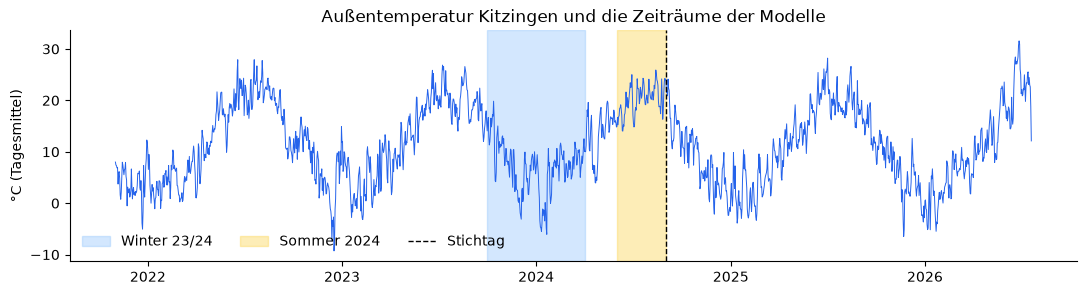

In [6]:
wetter = load_outdoor_temperature(stunden["timestamp"].min(), stunden["timestamp"].max())
print(f"Wetter: {wetter.shape[0]:,} Stunden, Spalten {list(wetter.columns)}")
print(wetter["t_out"].describe().round(1).to_string())
print(f"davon linear aufgefüllt (Lücken bis 6 h): {wetter['interpolated'].sum()} Stunden")
wetter = wetter.rename(columns={"t_out": "aussen"})[["timestamp", "aussen"]]
stunden = stunden.merge(wetter, on="timestamp", how="left")
print(f"\nAußentemperatur fehlt nach dem Anhängen in {stunden['aussen'].isna().mean():.2%} der Stunden")

tagesmittel = wetter.set_index("timestamp")["aussen"].resample("D").mean()
fig, ax = plt.subplots(figsize=(13, 3))
ax.plot(tagesmittel.index, tagesmittel, lw=0.7, color="#2563EB")
for (von, bis), farbe, name in ((WINTER, "#93C5FD", "Winter 23/24"), (SOMMER, "#FCD34D", "Sommer 2024")):
    ax.axvspan(von, bis, color=farbe, alpha=0.4, label=name)
ax.axvline(STICHTAG, color="black", ls="--", lw=1, label="Stichtag")
ax.set_ylabel("°C (Tagesmittel)")
ax.set_title("Außentemperatur Kitzingen und die Zeiträume der Modelle")
ax.legend(frameon=False, ncol=3, loc="lower left")
ax.spines[["top", "right"]].set_visible(False)
plt.show()

**Was macht diese Zelle?**
- Holt die stündliche Außentemperatur (beim ersten Lauf einmalig von DWD Open Data,
  danach aus dem Cache in `data/raw/weather/`) und hängt sie per Zeitstempel an.
- Die Grafik zeigt, welche Zeiträume die Modelle später benutzen. Alles links der
  gestrichelten Linie ist vor den Begehungen.

## 4 · Wie viele brauchbare Tage hat jeder Zähler?

Die LSTM-Modelle in Notebook 20 und 21 lesen ganze Tage, also 24 Stunden am Stück.
Ein Tag zählt nur, wenn **alle 24 Stunden aller Größen** gemessen sind. Lücken zu
füllen hieße, dem Netz erfundene Stunden beizubringen.

In [7]:
KANAELE = ["vorlauf", "ruecklauf", "spreizung", "durchfluss", "leistung", "aussen"]
stunden["tag"] = stunden["timestamp"].dt.floor("D")
stunden["vollstaendig"] = stunden[KANAELE].notna().all(axis=1)
tage = stunden.groupby(["zaehler", "tag"])["vollstaendig"].sum().rename("stunden").reset_index()
tage["voll"] = tage["stunden"] == 24

ZEITRAEUME = {
    "Winter 22/23": ("2022-10-01", "2023-04-01"),
    "Winter 23/24": ("2023-10-01", "2024-04-01"),
    "Sommer 2024": ("2024-06-01", "2024-09-01"),
    "ab Stichtag": ("2024-09-01", "2030-01-01"),
}
volle_tage = pd.DataFrame({
    name: tage[(tage["tag"] >= von) & (tage["tag"] < bis) & tage["voll"]].groupby("zaehler").size()
    for name, (von, bis) in ZEITRAEUME.items()
}).reindex(stunden["zaehler"].unique()).fillna(0).astype(int)
volle_tage.index.name = "zaehler"
print(f"Vollständige Tage insgesamt: {tage['voll'].sum():,} von {len(tage):,}")
volle_tage.describe().round(0)

Vollständige Tage insgesamt: 67,840 von 88,792


,Winter 22/23,Winter 23/24,Sommer 2024,ab Stichtag
count,93.0,93.0,93.0,93.0
mean,60.0,156.0,78.0,294.0
std,68.0,47.0,28.0,127.0
min,0.0,0.0,0.0,0.0
25%,0.0,143.0,89.0,298.0
50%,0.0,180.0,90.0,308.0
75%,137.0,180.0,90.0,309.0
max,138.0,181.0,90.0,680.0


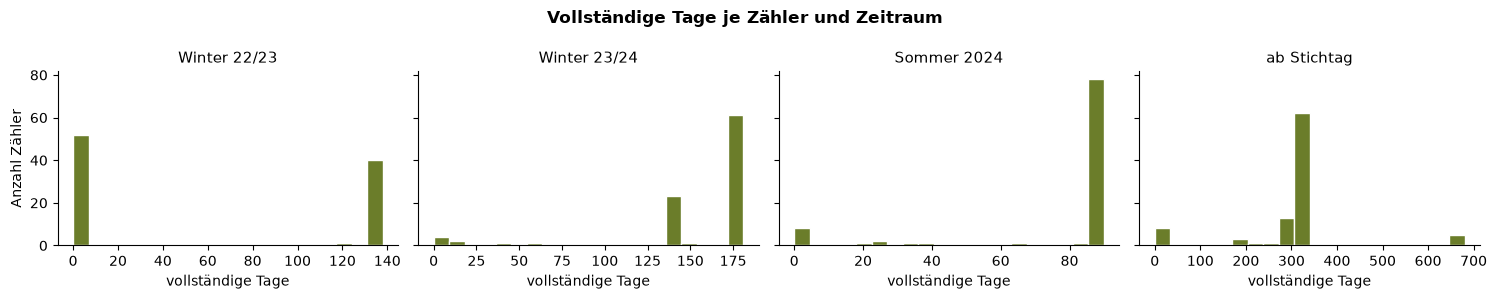

In [8]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3), sharey=True)
for ax, name in zip(axes, volle_tage.columns):
    ax.hist(volle_tage[name], bins=20, color="#6B7D2A", edgecolor="white")
    ax.set_title(name, fontsize=11)
    ax.set_xlabel("vollständige Tage")
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("Anzahl Zähler")
fig.suptitle("Vollständige Tage je Zähler und Zeitraum", fontweight="bold")
fig.tight_layout()
plt.show()

**Was machen die beiden Zellen?**
- Je Zähler und Kalendertag wird gezählt, wie viele Stunden *alle* sechs Größen haben.
  Nur Tage mit 24 solchen Stunden sind „voll“.
- Die Tabelle zählt die vollen Tage je Zeitraum. Ein Winter hat 182 Tage, der Sommer 92.
- Am Tag der Zeitumstellung im März hat ein Tag nur 23 Stunden. Er fällt deshalb immer
  heraus; das kostet einen Tag im Jahr.

**Was die Tabelle sagt**

- Von knapp 89.000 Zähler-Tagen sind knapp 68.000 vollständig. Die übrigen haben Lücken, oft nur einzelne Stunden.
- **Winter 23/24 und Sommer 2024 sind gut abgedeckt:** Im Median hat ein Zähler 180 von 182 Wintertagen und 90 von 92 Sommertagen. Auf diesen beiden Zeiträumen bauen die Modelle auf.
- **Winter 22/23 hat nur knapp die Hälfte:** 41 Zähler haben dort mindestens 60 volle Tage, der Rest wurde erst 2023 nachgerüstet (siehe die zwei Rollout-Wellen in Notebook 00). Vergleiche über zwei Winter (Notebook 20) gehen deshalb nur mit diesen 41 Zählern.
- Nach dem Stichtag hat ein typischer Zähler gut 300 volle Tage, genug, um in Notebook 21 die Zeit nach den Begehungen zu beobachten.

## 5 · Labels aus den Begehungen

Was ein Modell erkennen soll, steht im Begehungsprotokoll (66 Begehungen). Es gibt
zwei Quellen:

* **Kästchen** (`src/inspections.py`): Filter gereinigt, Durchfluss eingestellt,
  Leitungen gedämmt, Stellmotor bzw. Stellventil getauscht, Vertragsleistung alt/neu.
* **Freitext** „Sonstiges“ (`src/befundcodes.py`): Viele Befunde stehen nur dort,
  etwa ein klemmendes Regelventil.

Zuerst ein Blick darauf, wie die Kästchen ausgefüllt wurden — das wird am Ende
erklären, warum manche Fehlerarten nicht lernbar sind.

In [9]:
roh = load_inspections()
# Die Rohtabelle enthält Adressen. Deshalb nur Größe und Spaltennamen ansehen, keine Zeilen.
print(f"Begehungsprotokoll: {roh.shape[0]} Zeilen × {roh.shape[1]} Spalten")
print("Spalten (Auswahl):", [c.replace("\n", " ") for c in roh.columns[:12]], "...")

Begehungsprotokoll: 66 Zeilen × 134 Spalten
Spalten (Auswahl): ['Nr.', 'Datum', 'Straßenname', 'Hausnummer', 'Dauer (Uhrzeit)', 'Dauer (Uhrzeit)', 'Anlagen- konfiguration auf Seite 125', 'Station auf Seite 125', 'Zusatz- heizungen', 'Anzahl Personen', 'beheizte Wohnfläche', 'Inbetriebnahmejahr'] ...


**Was macht diese Zelle?**
- Lädt das Begehungsprotokoll (66 Begehungen, über 100 Spalten mit zweizeiligem Kopf).
- Wir schauen nur auf die Größe und die ersten Spaltennamen. Die Zeilen enthalten Straße
  und Hausnummer und werden deshalb in keinem dieser Notebooks angezeigt.

In [10]:
KAESTCHEN = {
    "Filter gereinigt": "Filter\ngereinigt",
    "Durchfluss eingestellt": "Durchfluss neu\neingestellt",
    "Leitungen gedämmt": "Leitungen\nneu gedämmt",
    "Stellmotor getauscht": "Stellmotor\ngetauscht",
    "Stellventil getauscht": "Stellventil\ngetauscht",
}

def zustand(wert):
    w = str(wert).strip().lower()
    if w == "ja":
        return "ja"
    if w == "nein":
        return "ausdrücklich nein"
    return "leer"

ausfuellung = pd.DataFrame({name: roh[spalte].map(zustand).value_counts() for name, spalte in KAESTCHEN.items()}).T
ausfuellung = ausfuellung.reindex(columns=["ja", "ausdrücklich nein", "leer"]).fillna(0).astype(int)
ausfuellung

,ja,ausdrücklich nein,leer
Filter gereinigt,31,4,31
Durchfluss eingestellt,23,6,37
Leitungen gedämmt,23,8,35
Stellmotor getauscht,2,11,53
Stellventil getauscht,2,12,52


**Was macht diese Zelle?**
- Liest das Protokoll roh und zählt je Kästchen, wie oft „ja“, wie oft ausdrücklich
  „nein“ und wie oft gar nichts eingetragen ist.

**Was die Tabelle sagt**

- Die Kästchen wurden fast nur dann ausgefüllt, wenn etwas gemacht wurde. Ein ausdrückliches „nein“ steht beim Filter 4-mal, beim Durchfluss 6-mal, bei der Dämmung 8-mal. In jeweils rund der Hälfte der Zeilen steht gar nichts.
- Für ein Modell heißt das: Die **Gegenbeispiele** („kein Filterproblem“) sind fast alle *leere* Kästchen. Ob dort wirklich nichts war, weiß niemand. Wer „leer“ als „nein“ liest, trifft eine Annahme.
- Stellmotor und Stellventil sind jeweils nur 2-mal angekreuzt. Die meisten Ventilbefunde stehen im **Freitext**. Deshalb nimmt das Ventil-Label beide Quellen zusammen.

In [11]:
tidy = inspections.tidy_inspections()
zaehler_mit_reihe = set(stunden["zaehler"].unique())
kodiert = befundcodes.kodiere_begehungen(load_begehungen.begehungen_mit_zaehler(available=zaehler_mit_reihe))

# Beide Loader lesen dieselben 66 Zeilen in derselben Reihenfolge - das wird hier geprüft,
# bevor die Spalten nebeneinandergelegt werden.
assert len(tidy) == len(kodiert) and (tidy["address_norm"].values == kodiert["key"].values).all()

soll_alt = pd.to_numeric(kodiert["rw_soll_tag_alt"], errors="coerce")
soll_neu = pd.to_numeric(kodiert["rw_soll_tag_neu"], errors="coerce")
vertrag_bekannt = tidy["vertrag_alt_kw"].notna() & tidy["vertrag_neu_kw"].notna()

begehungen = pd.DataFrame({
    "zaehler": kodiert["meter"].astype(int),
    "datum": pd.to_datetime(kodiert["datum"], errors="coerce"),
    "ventil": tidy["stellventil_getauscht"] | tidy["stellmotor_getauscht"] | kodiert["ventil_stellantrieb"],
    "daemmung": tidy["daemmung_neu"] | kodiert["daemmung"],
    "filter": tidy["filter_gereinigt"],
    "durchfluss": tidy["durchfluss_neu"],
    "temperatur": soll_neu < soll_alt,
    "ueberdimensioniert": (tidy["vertrag_neu_kw"] < tidy["vertrag_alt_kw"]).astype(float).where(vertrag_bekannt),
    # Vertragsleistung, wie sie VOR der Begehung galt (für die Auslastung in Abschnitt 6)
    "vertrag_alt_kw": tidy["vertrag_alt_kw"],
    "vertrag_neu_kw": tidy["vertrag_neu_kw"],
    # Straße nur als Nummer: dient später dazu, ganze Straßen gemeinsam auszulassen
    "strasse_gruppe": pd.factorize(tidy["address_norm"].str.rsplit(" ", n=1).str[0])[0],
})
print(f"{len(begehungen)} Begehungen, {begehungen['zaehler'].nunique()} verschiedene Zähler, "
      f"davon mit Zeitreihe: {begehungen['zaehler'].isin(zaehler_mit_reihe).sum()} Begehungen")
begehungen.head()

66 Begehungen, 62 verschiedene Zähler, davon mit Zeitreihe: 59 Begehungen


,zaehler,datum,ventil,daemmung,filter,durchfluss,temperatur,ueberdimensioniert,vertrag_alt_kw,vertrag_neu_kw,strasse_gruppe
0,72167782,NaT,True,True,False,True,True,NaN,NaN,NaN,0
1,68956367,2025-09-12,False,False,True,False,True,0.0,8.0,8.0,0
2,68956348,2024-09-09,False,False,True,True,False,NaN,NaN,NaN,0
3,68956353,2024-09-23,False,True,False,True,True,0.0,8.0,8.0,1
4,80912195,2024-09-11,False,False,False,False,False,NaN,NaN,NaN,1


In [12]:
# Kurzer Blick auf die neue Tabelle: Datentypen und wie viele Werte je Spalte fehlen
werte = begehungen.drop(columns=["zaehler", "strasse_gruppe"]).select_dtypes(["bool", "number"])
pd.DataFrame({"Typ": begehungen.dtypes.astype(str), "fehlend": begehungen.isna().sum(),
              "Anteil ja / Mittelwert": werte.mean().round(2)})

,Typ,fehlend,Anteil ja / Mittelwert
daemmung,bool,0,0.39
datum,datetime64[us],8,NaN
durchfluss,bool,0,0.35
filter,bool,0,0.47
strasse_gruppe,int64,0,NaN
temperatur,bool,0,0.56
ueberdimensioniert,float64,22,0.20
ventil,bool,0,0.17
vertrag_alt_kw,float64,22,10.36
vertrag_neu_kw,float64,19,10.19


**Was macht diese Zelle?**
- `tidy_inspections()` liefert die Kästchen, `kodiere_begehungen()` die Freitext-Befunde
  samt Zählernummer. Bei Adressen mit Zählerwechsel wird der Zähler gewählt, für den es
  eine Zeitreihe gibt.
- Je Begehung entstehen sechs Labels:

| Label | ja, wenn … |
|---|---|
| `ventil` | Stellventil oder Stellmotor getauscht **oder** Ventilbefund im Freitext |
| `daemmung` | Leitungen gedämmt **oder** Dämmungsbefund im Freitext |
| `filter` | Filter gereinigt |
| `durchfluss` | Durchfluss neu eingestellt |
| `temperatur` | Rücklauf-Sollwert tagsüber gesenkt |
| `ueberdimensioniert` | Vertragsleistung neu kleiner als alt (leer, wenn nicht beide eingetragen) |

- **Lesart „leer ist nein“:** Ein leeres Kästchen zählt als „nein“. Das ist eine
  Annahme — die Tabelle oben zeigt, wie stark sie trägt.
- Die zweite Tabelle ist der Blick auf das Ergebnis: Je Begehung sind die Kästchen-Labels
  immer gefüllt (wegen „leer ist nein“). Bei 8 Begehungen fehlt das Datum, bei 22 die
  Vertragsleistung, deshalb ist „überdimensioniert“ dort leer.
- Die Adresse wird nur für den Abgleich gebraucht und nicht weitergegeben. Übrig bleibt
  eine Nummer je Straße.

In [13]:
LABELS = ["ventil", "daemmung", "filter", "durchfluss", "temperatur", "ueberdimensioniert"]
labels = begehungen.groupby("zaehler").agg(
    begehungen=("datum", "size"),
    erste_begehung=("datum", "min"),
    strasse_gruppe=("strasse_gruppe", "first"),
    vertrag_alt_kw=("vertrag_alt_kw", "first"),
    vertrag_neu_kw=("vertrag_neu_kw", "first"),
    **{name: (name, "max") for name in LABELS},
)
labels = labels[labels.index.isin(zaehler_mit_reihe)]
for name in LABELS[:-1]:
    labels[name] = labels[name].astype(bool)

basisraten = pd.DataFrame({
    "Fälle": labels[LABELS].sum().astype(int),
    "bekannt": labels[LABELS].notna().sum(),
})
basisraten["Anteil"] = (basisraten["Fälle"] / basisraten["bekannt"]).round(2)
print(f"{len(labels)} begangene Zähler mit Zeitreihe; {(labels['begehungen'] > 1).sum()} davon mehrfach begangen")
print(f"Begehungen vor dem Stichtag: {(labels['erste_begehung'] < STICHTAG).sum()}")
basisraten

56 begangene Zähler mit Zeitreihe; 3 davon mehrfach begangen
Begehungen vor dem Stichtag: 2


,Fälle,bekannt,Anteil
ventil,11,56,0.20
daemmung,23,56,0.41
filter,26,56,0.46
durchfluss,20,56,0.36
temperatur,36,56,0.64
ueberdimensioniert,9,37,0.24


**Was macht diese Zelle?**
- Fasst die Begehungen je Zähler zusammen. Wurde ein Zähler zweimal begangen, gilt ein
  Befund, wenn er bei irgendeiner der Begehungen gefunden wurde.
- Die Tabelle zeigt die **Basisraten**: wie viele Fälle es je Fehlerart gibt. Ein
  Modell muss besser sein als blindes Raten mit genau diesem Anteil.

**Was die Tabelle sagt**

- 56 begangene Zähler haben eine Zeitreihe. Nur 2 davon wurden vor dem Stichtag begangen (August 2024), die meisten im September 2024.
- **Ventil:** 11 Fälle, also 20 %. Eine zufällige Liste der ersten zehn Zähler enthielte im Mittel 2 Ventilfälle. Das ist die Messlatte für Precision@10 in den folgenden Notebooks.
- **Dämmung** (23) und **Durchfluss** (20) liegen um 40 %, **Filter** (26) fast bei der Hälfte.
- **Temperatur:** Der Sollwert wurde bei knapp zwei Dritteln gesenkt. Das ist eher die Regel als ein Befund.
- **Überdimensioniert:** Hier ist das Label nur für 37 Zähler bekannt, weil die Vertragsleistung nicht überall alt *und* neu eingetragen ist. 9 davon wurden verkleinert.

## 6 · Kennzahlen vor der Begehung

Für die klassischen Modelle (logistische Regression, XGBoost) und für das K-Means in
Notebook 19 braucht es je Zähler **eine Zeile mit Zahlen**. Jede Kennzahl steht für ein
Fehlerbild und wird nur aus Daten **vor der ersten Begehung** gerechnet — spätestens
bis zum Stichtag.

| Kennzahl | Zeitraum | Rechnung | Fehlerbild |
|---|---|---|---|
| `sommer_nachtfluss_lph` | Sommer 2024, 0–5 Uhr | Median des Durchflusses | Wasser läuft durch, obwohl niemand heizt → Ventil schließt nicht |
| `sommer_durchlauf_anteil` | Sommer 2024, 0–5 Uhr | Anteil der Stunden mit ≥ 5 l/h | dasselbe, robust gegen einzelne Spitzen |
| `sommer_nacht_spreizung_k` | Sommer 2024, 0–5 Uhr | Median der Spreizung, wenn Wasser fließt | kaum Spreizung = Wasser läuft ungenutzt durch |
| `winter_ruecklauf_bei_0c` | Winter 23/24 | Gerade Tagesmittel Rücklauf gegen Außentemperatur, Wert bei 0 °C | schlechte Auskühlung, wetterbereinigt |
| `winter_spreizung_last_k` | Winter 23/24 | mittlere Spreizung in Stunden mit Leistung > 0,5 kW | schlechter Wärmeübergang |
| `winter_ruecklauf_p90` | Winter 23/24 | 90-%-Quantil des Rücklaufs | zeitweise sehr heißer Rücklauf |
| `winter_fluss_cv` | Winter 23/24 | Streuung / Mittel des Durchflusses unter Last | unruhige Regelung |
| `winter_nacht_tag_fluss` | Winter 23/24 | Durchfluss 0–5 Uhr / 8–20 Uhr (Mediane) | fehlende Nachtabsenkung |
| `auslastung` | Winter 23/24 | 99-%-Quantil der Leistung / Anschlusswert aus `Nodes_Edges.ods` | überdimensionierter Anschluss |
| `auslastung_vertrag` | Winter 23/24 | 99-%-Quantil der Leistung / Vertragsleistung **vor** der Begehung (Protokoll) | dasselbe, nur für begangene Zähler (Begründung in Abschnitt 6) |
| `sommerlast_anteil` | 09/2023–08/2024 | mittlere Leistung im Sommer / im ganzen Jahr | hohe Grundlast (Zirkulation, Verluste) |

Für die Einstufung in Notebook 19 kommen drei Größen hinzu, die beschreiben, **wie**
eine Station ihre Leistung regelt (Winter 23/24, nur Stunden mit Leistung > 0,5 kW,
Durchfluss > 1 l/h und Spreizung > 1 K):

| Kennzahl | Rechnung | Bedeutung |
|---|---|---|
| `anteil_volumenstrom` | cov(log P, log V) / var(log P) | nahe 1: der Durchfluss folgt der Last; nahe 0: er läuft konstant weiter |
| `streubreite_betriebspunkte` | √(var log V + var log ΔT) | gleichbleibender gegen springenden Betrieb |
| `ruecklauf_lastgewichtet` | Mittel des Rücklaufs, gewichtet mit der Leistung | wie heiß das Wasser zurückkommt, wenn es darauf ankommt |

In [14]:
MIN_LASTSTUNDEN = 200


def kennzahlen(g):
    w = g[(g["timestamp"] >= WINTER[0]) & (g["timestamp"] < WINTER[1])]
    s = g[(g["timestamp"] >= SOMMER[0]) & (g["timestamp"] < SOMMER[1])]
    k = {"stunden_winter": int(w["durchfluss"].notna().sum()), "stunden_sommer": int(s["durchfluss"].notna().sum())}

    # Sommernächte
    nacht = s[s["timestamp"].dt.hour <= 5].dropna(subset=["durchfluss"])
    fliesst = nacht[nacht["durchfluss"] >= 5]
    k["sommer_nachtfluss_lph"] = nacht["durchfluss"].median()
    k["sommer_durchlauf_anteil"] = (nacht["durchfluss"] >= 5).mean() if len(nacht) else np.nan
    k["sommer_nacht_spreizung_k"] = fliesst["spreizung"].median() if len(fliesst) >= 20 else np.nan

    # Winter
    tag = w.groupby(w["timestamp"].dt.floor("D"))[["ruecklauf", "aussen"]].mean().dropna()
    tag = tag[tag["aussen"] <= 15]
    k["winter_ruecklauf_bei_0c"] = np.polyfit(tag["aussen"], tag["ruecklauf"], 1)[1] if len(tag) >= 30 else np.nan
    last = w[(w["leistung"] > 0.5) & (w["durchfluss"] > 1) & (w["spreizung"] > 1)].dropna(subset=["ruecklauf"])
    k["winter_spreizung_last_k"] = last["spreizung"].mean()
    k["winter_ruecklauf_p90"] = w["ruecklauf"].quantile(0.9)
    k["winter_fluss_cv"] = last["durchfluss"].std() / last["durchfluss"].mean() if len(last) else np.nan
    tags = w.loc[w["timestamp"].dt.hour.between(8, 20), "durchfluss"].median()
    nachts = w.loc[w["timestamp"].dt.hour <= 5, "durchfluss"].median()
    k["winter_nacht_tag_fluss"] = nachts / tags if tags > 0 else np.nan
    k["winter_spitzenlast_kw"] = w["leistung"].quantile(0.99)
    jahr = g[(g["timestamp"] >= "2023-09-01") & (g["timestamp"] < "2024-09-01")]
    k["sommerlast_anteil"] = s["leistung"].mean() / jahr["leistung"].mean() if jahr["leistung"].mean() > 0 else np.nan

    # Wie regelt die Station? (für Notebook 19) - leer, wenn es zu wenige Laststunden gibt
    k["anteil_volumenstrom"] = k["streubreite_betriebspunkte"] = k["ruecklauf_lastgewichtet"] = np.nan
    if len(last) >= MIN_LASTSTUNDEN:
        log_p, log_v, log_d = np.log(last["leistung"]), np.log(last["durchfluss"]), np.log(last["spreizung"])
        k["anteil_volumenstrom"] = np.cov(log_p, log_v, bias=True)[0, 1] / np.var(log_p)
        k["streubreite_betriebspunkte"] = np.sqrt(np.var(log_v) + np.var(log_d))
        k["ruecklauf_lastgewichtet"] = np.average(last["ruecklauf"], weights=last["leistung"])
    return pd.Series(k)


# Jeder Zähler nur bis zu seiner ersten Begehung, spätestens bis zum Stichtag
grenze = labels["erste_begehung"].clip(upper=STICHTAG).reindex(sorted(zaehler_mit_reihe)).fillna(STICHTAG)
vor = stunden[stunden["timestamp"] < stunden["zaehler"].map(grenze)]
kz = vor.groupby("zaehler").apply(kennzahlen)

anschluss = pd.read_csv(PROCESSED / "hast_features.csv").set_index("Zählernummer")["anschlusswert_kw"]
kz["auslastung"] = kz["winter_spitzenlast_kw"] / anschluss.reindex(kz.index)
kz["auslastung_vertrag"] = kz["winter_spitzenlast_kw"] / labels["vertrag_alt_kw"].reindex(kz.index)
kz = kz.drop(columns="winter_spitzenlast_kw")
print(f"{len(kz)} Zähler, {kz.shape[1]} Spalten")
kz.round(2).head(10)

91 Zähler, 16 Spalten


,stunden_winter,stunden_sommer,sommer_nachtfluss_lph,sommer_durchlauf_anteil,sommer_nacht_spreizung_k,winter_ruecklauf_bei_0c,winter_spreizung_last_k,winter_ruecklauf_p90,winter_fluss_cv,winter_nacht_tag_fluss,sommerlast_anteil,anteil_volumenstrom,streubreite_betriebspunkte,ruecklauf_lastgewichtet,auslastung,auslastung_vertrag
zaehler,,,,,,,,,,,,,,,,
53198226,3467.0,2206.0,10.0,0.66,14.2,44.78,32.07,54.50,0.65,0.34,0.10,0.96,0.83,42.95,1.31,NaN
58177363,4389.0,0.0,NaN,NaN,NaN,42.14,32.33,47.60,0.62,0.62,NaN,0.84,0.60,39.22,NaN,NaN
58177384,923.0,0.0,NaN,NaN,NaN,57.14,25.31,57.50,0.47,0.58,NaN,1.17,0.59,51.06,NaN,NaN
58202380,4386.0,0.0,NaN,NaN,NaN,56.75,NaN,68.20,NaN,1.08,NaN,NaN,NaN,NaN,NaN,NaN
61620222,4391.0,0.0,NaN,NaN,NaN,46.59,24.54,58.50,0.71,0.00,NaN,0.97,0.91,44.58,NaN,NaN
65273846,4390.0,2206.0,0.0,0.01,NaN,28.73,37.22,41.50,0.81,0.00,0.31,1.02,0.65,31.26,1.84,1.84
66761022,4381.0,0.0,NaN,NaN,NaN,61.24,12.63,71.00,0.37,0.85,NaN,0.56,0.64,62.33,0.48,NaN
68956339,3773.0,2197.0,0.0,0.00,NaN,48.89,24.45,59.50,0.58,0.39,0.09,0.89,0.71,49.33,0.78,NaN
68956342,4390.0,2206.0,0.0,0.18,21.5,48.37,26.83,51.71,0.83,0.42,0.08,0.99,0.91,43.81,0.79,NaN


In [15]:
kz.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
stunden_winter,91.0,3963.21,875.78,0.00,3467.00,4390.00,4390.00,4391.00
stunden_sommer,91.0,1974.82,624.63,0.00,2205.00,2206.00,2206.00,2206.00
sommer_nachtfluss_lph,85.0,143.52,616.79,0.00,0.00,0.00,23.50,5165.00
sommer_durchlauf_anteil,85.0,0.36,0.38,0.00,0.06,0.16,0.71,1.00
sommer_nacht_spreizung_k,71.0,12.12,10.07,-14.70,2.55,12.00,18.60,35.70
winter_ruecklauf_bei_0c,88.0,47.26,9.89,28.48,41.98,46.20,53.20,68.99
winter_spreizung_last_k,89.0,25.12,8.36,4.02,20.61,27.43,30.57,39.80
winter_ruecklauf_p90,90.0,57.93,10.37,33.61,51.73,56.55,64.32,80.62
winter_fluss_cv,89.0,0.56,0.24,0.08,0.42,0.60,0.71,1.07
winter_nacht_tag_fluss,83.0,0.68,0.40,0.00,0.40,0.66,1.02,2.15


**Was man in der Übersicht prüft**
- `count`: für wie viele der 91 Zähler die Kennzahl berechnet werden konnte. Von den 93 Zählern aus Notebook 00 fehlen 80912191 und 81019433: Sie haben vor dem Stichtag keine Messwerte.
- `min` und `max`: ob die Werte physikalisch Sinn ergeben. Ein Durchlaufanteil liegt zwischen 0 und 1, ein
  Rücklauf bei 0 °C typischerweise zwischen 30 und 70 °C.
- `auslastung_vertrag` gibt es nur für begangene Zähler, weil die Vertragsleistung vor der Begehung
  nur im Begehungsprotokoll steht.

### Ein Datenfehler, der erst beim Hinsehen auffällt

Zwei Bezugsgrößen für die Auslastung: der **Anschlusswert** aus `Nodes_Edges.ods` und die
**Vertragsleistung vor der Begehung** aus dem Protokoll. Eigentlich sollten sie gleich
sein. Die Zelle vergleicht sie bei den Zählern, deren Vertrag bei der Begehung
**verkleinert** wurde.

In [16]:
vertrag = labels[["vertrag_alt_kw", "vertrag_neu_kw"]].dropna().join(anschluss.rename("anschlusswert_kw"))
verkleinert = vertrag[vertrag["vertrag_neu_kw"] < vertrag["vertrag_alt_kw"]]
gleich_neu = (verkleinert["anschlusswert_kw"] == verkleinert["vertrag_neu_kw"]).sum()
gleich_alt = (verkleinert["anschlusswert_kw"] == verkleinert["vertrag_alt_kw"]).sum()
print(f"{len(verkleinert)} Verträge wurden bei der Begehung verkleinert.")
print(f"  Anschlusswert in Nodes_Edges = NEUER Wert: {gleich_neu}")
print(f"  Anschlusswert in Nodes_Edges = alter Wert: {gleich_alt}")
verkleinert

9 Verträge wurden bei der Begehung verkleinert.
  Anschlusswert in Nodes_Edges = NEUER Wert: 7
  Anschlusswert in Nodes_Edges = alter Wert: 2


,vertrag_alt_kw,vertrag_neu_kw,anschlusswert_kw
zaehler,,,
68956347,12.0,10.0,10.0
68956356,8.0,6.0,8.0
68956371,8.0,6.0,6.0
68956372,8.0,6.0,6.0
72135486,8.0,6.0,8.0
72167783,17.0,13.0,13.0
80912173,10.0,8.0,8.0
80912180,14.0,12.0,12.0
80912197,10.0,8.0,8.0


**Was das bedeutet**

`Nodes_Edges.ods` wurde offenbar **nach** den Begehungen gepflegt. Bei den meisten verkleinerten
Verträgen steht dort schon der neue, kleinere Wert. Wer die Auslastung auf den Anschlusswert
bezieht, sieht bei genau diesen Stationen eine normale Auslastung, und das Signal
„überdimensioniert“ ist verschwunden. In der lokalen Vorarbeit war die Bezugsgröße der alte
Vertrag, und dort war die Überdimensionierung mit XGBoost erkennbar (AUC bis 0,87).

**Folge:** Zum Lernen und Prüfen nimmt Notebook 22 die `auslastung_vertrag`. Für nie begangene
Zähler, die kein Protokoll haben, bleibt nur der Anschlusswert. Für sie ist er aber der aktuelle
Vertrag, also die richtige Größe.

**Was macht diese Zelle?**
- `kennzahlen()` bekommt die Stunden **eines** Zählers und gibt eine Zeile mit allen
  Kennzahlen zurück. Jede Zeile der Funktion entspricht einer Zeile der Tabelle oben.
- `grenze` schneidet je Zähler alles ab der ersten Begehung ab (spätestens ab dem
  Stichtag). Bei den Zählern, die schon im August 2024 begangen wurden, fehlt damit
  ein Teil des Sommers. Dafür sieht kein Modell eine Station nach ihrer Reparatur.
- Gibt es zu wenige Stunden (zum Beispiel keine 200 Laststunden), bleibt das Feld leer,
  statt eine Zahl aus Rauschen zu erfinden.
- Die Auslastung nutzt den Anschlusswert aus Notebook 00 (aus `Nodes_Edges.ods`).

In [17]:
# Von Hand nachgerechnet: Sommer-Nachtdurchfluss des Beispielzählers
g = stunden[(stunden["zaehler"] == BEISPIEL) & (stunden["timestamp"] >= SOMMER[0])
            & (stunden["timestamp"] < min(SOMMER[1], grenze[BEISPIEL]))]
naechte = g[g["timestamp"].dt.hour <= 5]["durchfluss"].dropna()
print(f"Zähler {BEISPIEL}: {len(naechte)} Nachtstunden im Sommer 2024, Median {naechte.median():.1f} l/h")
assert np.isclose(naechte.median(), kz.loc[BEISPIEL, "sommer_nachtfluss_lph"])
print("stimmt mit der Tabelle überein")

fehlend = kz.isna().sum()
print("\nFehlende Werte je Kennzahl (nur > 0):")
fehlend[fehlend > 0].to_frame("Zähler ohne Wert")

Zähler 68956347: 552 Nachtstunden im Sommer 2024, Median 0.0 l/h
stimmt mit der Tabelle überein

Fehlende Werte je Kennzahl (nur > 0):


,Zähler ohne Wert
sommer_nachtfluss_lph,6
sommer_durchlauf_anteil,6
sommer_nacht_spreizung_k,20
winter_ruecklauf_bei_0c,3
winter_spreizung_last_k,2
winter_ruecklauf_p90,1
winter_fluss_cv,2
winter_nacht_tag_fluss,8
sommerlast_anteil,6
anteil_volumenstrom,3


**Was macht diese Zelle?**
- Rechnet eine Kennzahl für einen Zähler noch einmal ohne die Funktion nach und prüft
  mit `assert`, dass dasselbe herauskommt.
- Zeigt, für wie viele Zähler eine Kennzahl fehlt — meistens, weil im Sommer 2024 oder
  im Winter 23/24 zu wenig gemessen wurde.

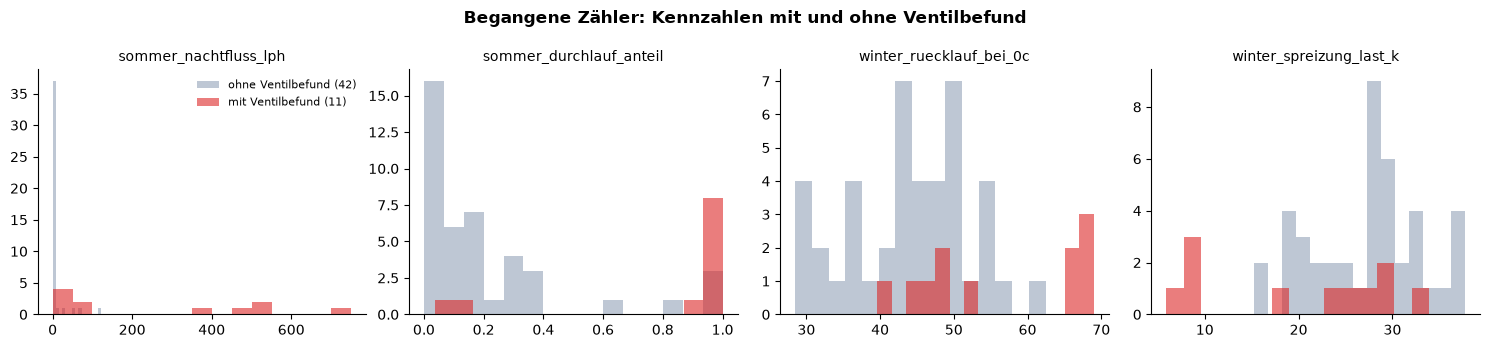

In [18]:
vergleich = kz.join(labels[["ventil", "daemmung"]], how="inner")
zeige = ["sommer_nachtfluss_lph", "sommer_durchlauf_anteil", "winter_ruecklauf_bei_0c", "winter_spreizung_last_k"]
fig, axes = plt.subplots(1, 4, figsize=(15, 3.5))
for ax, spalte in zip(axes, zeige):
    for wert, farbe, name in ((False, "#94A3B8", "ohne Ventilbefund"), (True, "#DC2626", "mit Ventilbefund")):
        werte = vergleich.loc[vergleich["ventil"] == wert, spalte].dropna()
        ax.hist(werte, bins=15, alpha=0.6, color=farbe, label=f"{name} ({len(werte)})")
    ax.set_title(spalte, fontsize=10)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].legend(frameon=False, fontsize=8)
fig.suptitle("Begangene Zähler: Kennzahlen mit und ohne Ventilbefund", fontweight="bold")
fig.tight_layout()
plt.show()

**Was macht diese Zelle?**
- Ein erster Blick, ob die Kennzahlen die Befunde überhaupt trennen: je Kennzahl ein
  Histogramm für begangene Zähler mit und ohne Ventilbefund.

**Was man sieht**

- **Der Sommer-Durchlaufanteil trennt das Ventil fast allein:** 9 der 11 Zähler mit Ventilbefund hatten im Sommer 2024 in mindestens 90 % der Nachtstunden Durchfluss. Ohne Befund sind es nur 3 von 42. Im Median liefen bei den Ventilfällen nachts 67 l/h durch, bei den anderen 0 l/h.
- **Auch im Winter unterscheiden sie sich:** Der Rücklauf bei 0 °C liegt bei den Ventilfällen im Median bei 53 °C statt 45 °C, die Spreizung unter Last ist kleiner (24,6 statt 28,2 K). Das passt zur Physik: Läuft Wasser ungenutzt durch, kommt es heiß zurück. Aber die Verteilungen überlappen stark.
- Das ist die Ausgangslage für die Modelle: Mit dem Sommer ist das Ventil leicht zu finden. Spannend wird, ob ein Modell es **schon im Winter** sieht und ob es für die anderen Fehlerarten überhaupt ein Signal gibt.

## 7 · Ergebnis speichern

In [19]:
stunden[["zaehler", "timestamp", *KANAELE]].to_parquet(PROCESSED / "modell_stunden.parquet", index=False)
kz.to_csv(PROCESSED / "modell_kennzahlen.csv")
labels.to_csv(PROCESSED / "modell_labels.csv")
for name in ("modell_stunden.parquet", "modell_kennzahlen.csv", "modell_labels.csv"):
    print(f"{name:26s} {(PROCESSED / name).stat().st_size / 1e6:6.1f} MB")

modell_stunden.parquet       18.6 MB
modell_kennzahlen.csv         0.0 MB
modell_labels.csv             0.0 MB


**Was macht diese Zelle?**
- Schreibt die drei Dateien, auf denen die Notebooks 19 bis 22 aufbauen. Alle liegen in
  `data/processed/` und sind damit nicht im Repo.
- `modell_labels.csv` enthält keine Adressen, nur Zählernummer, Datum, Labels und die
  Straßennummer.

## Zusammenfassung & Bewertung

### Was dieses Notebook geliefert hat

| Datei | Inhalt | gebraucht in |
|---|---|---|
| `modell_stunden.parquet` | 2,1 Mio. Stundenzeilen, 93 Zähler, mit Außentemperatur | 20, 21 |
| `modell_kennzahlen.csv` | 14 Kennzahlen je Zähler (91 Zähler), nur aus Daten vor der Begehung | 19, 20, 22 |
| `modell_labels.csv` | 6 Labels je begangenem Zähler (56), Datum, Straßennummer | 19–22 |

### Was belastbar ist

- **Die Datenbasis ist dieselbe wie in Notebook 00:** Dieselben 93 bereinigten Zählerreihen, nichts neu gefiltert.
- **Die zeitliche Trennung ist sauber:** Keine Kennzahl enthält Messungen nach der ersten Begehung eines Zählers.
- **Das Ventil hat ein klares Signal:** 9 von 11 Fällen laufen im Sommer nachts durch, gegen 3 von 42 ohne Befund.

### Was schwach ist

- **Wenige Fälle:** 11 Ventilfälle und 9 verkleinerte Verträge sind wenig. Jede Kennzahl, die später auf diesen Labels gemessen wird, braucht ein Unsicherheitsintervall.
- **Die Gegenbeispiele sind meist leere Kästchen.** Bei Filter, Durchfluss und Dämmung steht nur 4- bis 8-mal ein ausdrückliches „nein“. „Leer ist nein“ ist eine Annahme, die die Labels verwässern kann.
- **Temperatur** ist bei zwei Dritteln gesetzt und beschreibt eher, dass der Monteur fast überall den Sollwert gesenkt hat, als einen Fehler der Station.
- **Der Anschlusswert in `Nodes_Edges.ods` ist teilweise schon der Stand nach der Begehung.** Für die Überdimensionierung taugt er deshalb nicht als Bezug; dafür gibt es jetzt `auslastung_vertrag`.

### Was blockiert

- Für 37 der 93 Zähler gibt es keine Begehung und damit kein Label. Diese Zähler können nicht zum Prüfen dienen; die Modelle schätzen sie in Notebook 22 trotzdem ein.
- Zwei Winter vergleichen geht nur mit 41 Zählern, weil die übrigen erst 2023 nachgerüstet wurden.